In [1]:

import os
import sys
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount("/content/drive")

PROJECT = "/content/drive/MyDrive/simuteh-2330511089-"
SRC = os.path.join(PROJECT, "src")
DATA = os.path.join(PROJECT, "data", "sintetis")
HASIL = os.path.join(PROJECT, "hasil")

os.makedirs(HASIL, exist_ok=True)
sys.path.insert(0, SRC)

# Muat ulang modul agar tidak memakai versi lama di memori Colab
sys.modules.pop("utils_cv", None)
from utils_cv import baca, kontras_bercak

print("Folder proyek:", PROJECT)
print("Folder dataset tersedia:", os.path.isdir(DATA))
print("Folder hasil:", HASIL)

def konvolusi(img, k):
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2
    pad = np.pad(
        img.astype(float),
        ((ph, ph), (pw, pw)),
        mode="edge"
    )
    out = np.zeros(img.shape, dtype=float)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            jendela = pad[y:y+kh, x:x+kw]
            out[y, x] = np.sum(jendela * k)

    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):
    # Konvolusi sejati membalik kernel 180 derajat
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(
    baca(os.path.join(DATA, "bersih", nama)),
    cv2.COLOR_BGR2GRAY
)

kernel = {
    "rerata": np.ones((3, 3), dtype=float) / 9,
    "asimetris": np.array([
        [1, 0, -1],
        [2, 0, -2],
        [1, 0, -1]
    ], dtype=float)
}

for nm, k in kernel.items():
    t0 = time.perf_counter()
    manual = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0

    t0 = time.perf_counter()
    pustaka = cv2.filter2D(
        bersih, -1, k,
        borderType=cv2.BORDER_REPLICATE
    )
    t_cv = time.perf_counter() - t0

    sejati = konvolusi_sejati(bersih, k)

    beda = np.abs(
        manual.astype(int) - pustaka.astype(int)
    ).max()
    beda_sejati = np.abs(
        sejati.astype(int) - pustaka.astype(int)
    ).max()

    print(
        f"{nm}: manual vs filter2D={beda}; "
        f"konvolusi sejati vs filter2D={beda_sejati}; "
        f"waktu manual={t_manual:.3f} s; "
        f"waktu filter2D={t_cv:.5f} s"
    )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder proyek: /content/drive/MyDrive/simuteh-2330511089-
Folder dataset tersedia: True
Folder hasil: /content/drive/MyDrive/simuteh-2330511089-/hasil
rerata: manual vs filter2D=0; konvolusi sejati vs filter2D=0; waktu manual=3.421 s; waktu filter2D=0.02687 s
asimetris: manual vs filter2D=0; konvolusi sejati vs filter2D=255; waktu manual=2.046 s; waktu filter2D=0.00035 s


,derau,penapis,PSNR_dB,waktu_ms,KB
0,gauss_10,tanpa,28.11,0.00,3.11
1,gauss_10,rerata_3,36.86,0.30,5.25
2,gauss_10,rerata_5,37.59,0.43,5.51
3,gauss_10,gauss_5,37.67,1.11,5.41
4,gauss_10,median_3,35.48,0.30,5.14
5,gauss_10,median_5,38.27,2.76,5.98
6,gauss_10,median_9,38.17,57.70,6.79
7,gauss_20,tanpa,22.11,0.00,1.79
8,gauss_20,rerata_3,31.43,0.18,4.17
9,gauss_20,rerata_5,34.47,0.21,5.04


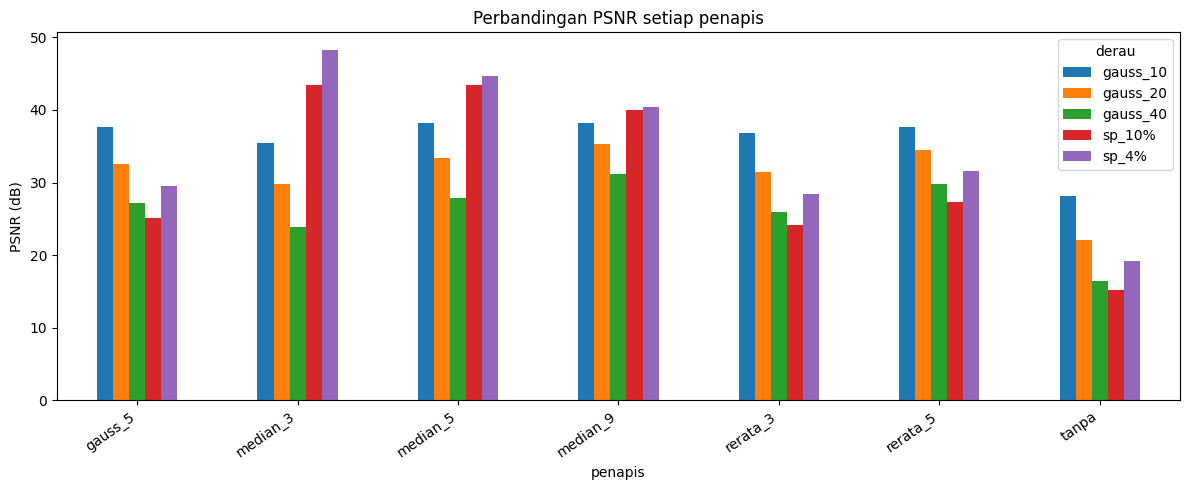

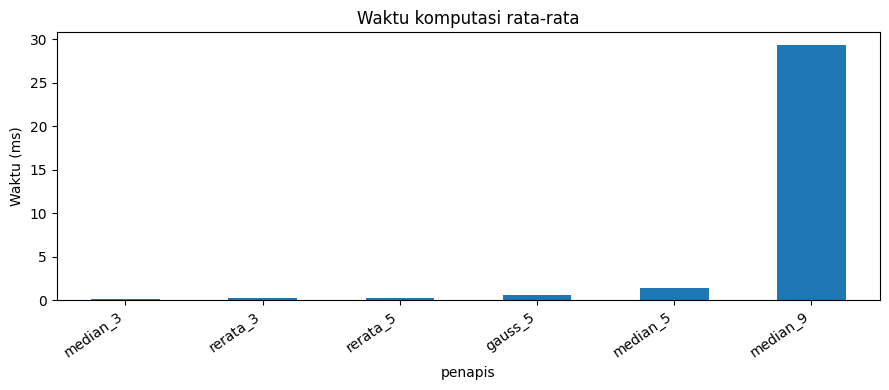

PSNR_dB        waktu_ms              KB      
derau    gauss_20  sp_4% gauss_20  sp_4% gauss_20 sp_4%
penapis                                                
gauss_5     32.56  29.46     0.42   0.46     4.50  3.76
median_3    29.73  48.29     0.15   0.15     3.70  6.24
median_5    33.42  44.73     1.07   1.09     4.90  6.51
median_9    35.34  40.47    23.09  20.40     5.60  7.05
rerata_3    31.43  28.37     0.18   0.20     4.17  3.45
rerata_5    34.47  31.61     0.21   0.22     5.04  4.44
tanpa       22.11  19.18     0.00   0.00     1.79  1.34

In [2]:

rng = np.random.default_rng(42)

md = cv2.imread(
    os.path.join(DATA, "mask_daun", nama), 0
)
mb = cv2.imread(
    os.path.join(DATA, "mask_bercak", nama), 0
)

def derau_gauss(img, sd):
    noise = rng.normal(0, sd, img.shape)
    return np.clip(
        img.astype(float) + noise, 0, 255
    ).astype(np.uint8)

def derau_sp(img, p):
    out = img.copy()
    m = rng.random(img.shape)
    out[m < p / 2] = 0
    out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):
    waktu = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        f(x)
        waktu.append(time.perf_counter() - t0)
    return 1000 * np.mean(waktu)

derau = {
    "gauss_10": derau_gauss(bersih, 10),
    "gauss_20": derau_gauss(bersih, 20),
    "gauss_40": derau_gauss(bersih, 40),
    "sp_4%": derau_sp(bersih, 0.04),
    "sp_10%": derau_sp(bersih, 0.10)
}

penapis = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "rerata_5": lambda x: cv2.blur(x, (5, 5)),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "median_9": lambda x: cv2.medianBlur(x, 9)
}

baris = []
for nama_derau, citra_derau in derau.items():
    baris.append([
        nama_derau, "tanpa",
        cv2.PSNR(bersih, citra_derau),
        0.0,
        kontras_bercak(citra_derau, md, mb)
    ])

    for nama_penapis, fungsi in penapis.items():
        hasil = fungsi(citra_derau)
        baris.append([
            nama_derau,
            nama_penapis,
            cv2.PSNR(bersih, hasil),
            ukur_waktu(fungsi, citra_derau),
            kontras_bercak(hasil, md, mb)
        ])

tabel = pd.DataFrame(
    baris,
    columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]
).round(2)

display(tabel)
tabel.to_csv(
    os.path.join(HASIL, "b4_tabel_penapis.csv"),
    index=False
)

# Grafik PSNR untuk semua kombinasi derau dan penapis
pivot_psnr = tabel.pivot(
    index="penapis", columns="derau", values="PSNR_dB"
)
pivot_psnr.plot(kind="bar", figsize=(12, 5))
plt.ylabel("PSNR (dB)")
plt.title("Perbandingan PSNR setiap penapis")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b4_grafik_psnr.png"),
    dpi=150
)
plt.show()

# Grafik waktu rata-rata penapis
waktu = (
    tabel[tabel.penapis != "tanpa"]
    .groupby("penapis")["waktu_ms"]
    .mean()
    .sort_values()
)
waktu.plot(kind="bar", figsize=(9, 4))
plt.ylabel("Waktu (ms)")
plt.title("Waktu komputasi rata-rata")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b4_grafik_waktu.png"),
    dpi=150
)
plt.show()

# Tabel 11: Gaussian SD 20 vs salt-and-pepper 4%
tabel11 = tabel[
    tabel.derau.isin(["gauss_20", "sp_4%"])
].pivot(
    index="penapis",
    columns="derau",
    values=["PSNR_dB", "waktu_ms", "KB"]
)
display(tabel11)
tabel11.to_csv(os.path.join(HASIL, "b4_tabel11.csv"))


,dI,KB
kernel,,
1,29.67,4.73
3,29.95,4.85
5,28.78,4.72
9,22.66,4.23
15,9.64,2.52


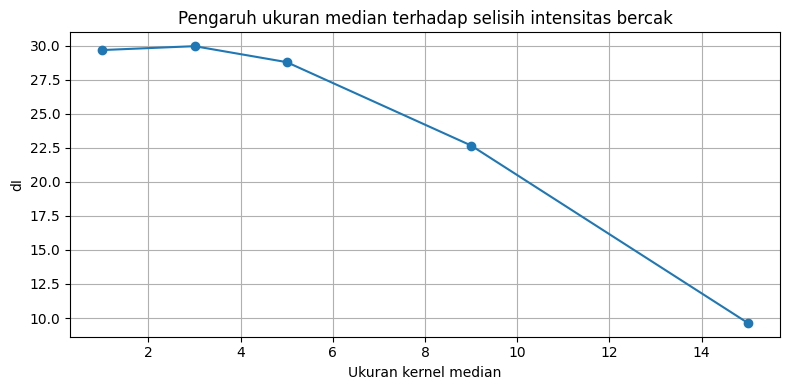

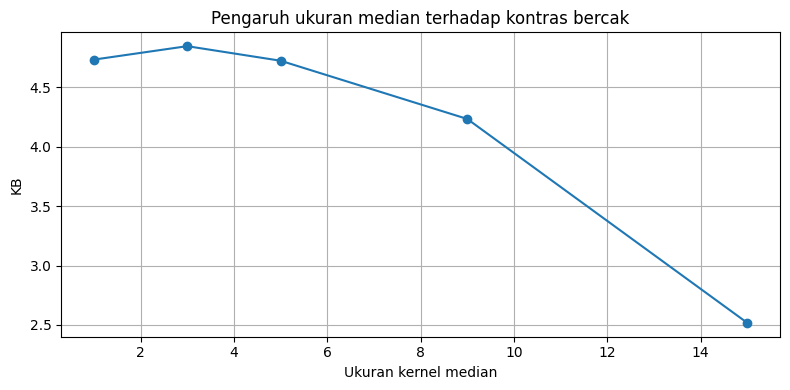

In [3]:

def selisih_rerata(kanal, mask_daun, mask_bercak):
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0

    if sehat.sum() == 0 or bercak.sum() == 0:
        return float("nan")

    return abs(k[bercak].mean() - k[sehat].mean())

label = pd.read_csv(os.path.join(DATA, "label.csv"))
baris = []

for nm in label[label["kelas"] == "ringan"]["nama_file"]:
    g = cv2.cvtColor(
        baca(os.path.join(DATA, "bersih", nm)),
        cv2.COLOR_BGR2GRAY
    )
    md2 = cv2.imread(os.path.join(DATA, "mask_daun", nm), 0)
    mb2 = cv2.imread(os.path.join(DATA, "mask_bercak", nm), 0)

    for k in [1, 3, 5, 9, 15]:
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([
            nm, k,
            selisih_rerata(out, md2, mb2),
            kontras_bercak(out, md2, mb2)
        ])

hasil_median = pd.DataFrame(
    baris, columns=["nama", "kernel", "dI", "KB"]
)
display(
    hasil_median.groupby("kernel")[["dI", "KB"]]
    .mean().round(2)
)

hasil_median.to_csv(
    os.path.join(HASIL, "b4_pengaruh_median.csv"),
    index=False
)

ringkasan = hasil_median.groupby("kernel")[["dI", "KB"]].mean()

plt.figure(figsize=(8, 4))
plt.plot(ringkasan.index, ringkasan["dI"], marker="o")
plt.xlabel("Ukuran kernel median")
plt.ylabel("dI")
plt.title("Pengaruh ukuran median terhadap selisih intensitas bercak")
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b4_grafik_dI_kernel.png"),
    dpi=150
)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(ringkasan.index, ringkasan["KB"], marker="o")
plt.xlabel("Ukuran kernel median")
plt.ylabel("KB")
plt.title("Pengaruh ukuran median terhadap kontras bercak")
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b4_grafik_KB_kernel.png"),
    dpi=150
)
plt.show()


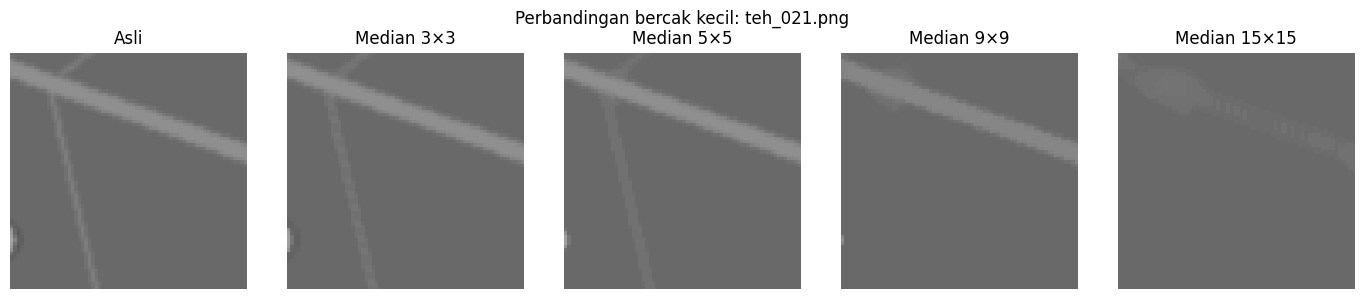

In [4]:

# Ambil satu citra kelas ringan yang memiliki mask bercak
contoh = None
for nm in label[label["kelas"] == "ringan"]["nama_file"]:
    mask = cv2.imread(os.path.join(DATA, "mask_bercak", nm), 0)
    if mask is not None and np.any(mask > 0):
        contoh = nm
        break

if contoh is None:
    raise ValueError("Tidak ditemukan mask bercak kelas ringan.")

g = cv2.cvtColor(
    baca(os.path.join(DATA, "bersih", contoh)),
    cv2.COLOR_BGR2GRAY
)
mb2 = cv2.imread(os.path.join(DATA, "mask_bercak", contoh), 0)

ys, xs = np.where(mb2 > 0)
cy, cx = int(np.mean(ys)), int(np.mean(xs))
radius = 35

y1, y2 = max(0, cy-radius), min(g.shape[0], cy+radius)
x1, x2 = max(0, cx-radius), min(g.shape[1], cx+radius)

crop_asli = g[y1:y2, x1:x2]
fig, axes = plt.subplots(1, 5, figsize=(14, 3))

axes[0].imshow(crop_asli, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Asli")

for ax, k in zip(axes[1:], [3, 5, 9, 15]):
    out = cv2.medianBlur(g, k)
    crop = out[y1:y2, x1:x2]
    ax.imshow(crop, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Median {k}×{k}")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"Perbandingan bercak kecil: {contoh}")
plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b4_crop_bercak_median.png"),
    dpi=150
)
plt.show()


In [5]:

def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0

for nm, redam in {
    "Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "Median": lambda x: cv2.medianBlur(x, 5)
}.items():
    A = redam(unsharp(noisy))  # tajamkan dahulu
    B = unsharp(redam(noisy))  # redam dahulu

    print(
        f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f}, "
        f"sigma_latar={A[latar].std():.1f}; "
        f"redam->tajam PSNR={cv2.PSNR(bersih, B):.2f}, "
        f"sigma_latar={B[latar].std():.1f}"
    )

# Kondisi normal: teh_001, teh_006, ..., teh_056
baris_normal = []
for nomor in range(1, 60, 5):
    nm = f"teh_{nomor:03d}.png"

    path_bersih = os.path.join(DATA, "bersih", nm)
    path_citra = os.path.join(DATA, "citra", nm)

    if not os.path.exists(path_bersih) or not os.path.exists(path_citra):
        print("Lewati, file tidak ditemukan:", nm)
        continue

    acuan = cv2.cvtColor(baca(path_bersih), cv2.COLOR_BGR2GRAY)
    input_noisy = cv2.cvtColor(baca(path_citra), cv2.COLOR_BGR2GRAY)

    hasil_filter = cv2.medianBlur(input_noisy, 3)

    baris_normal.append([
        nm,
        cv2.PSNR(acuan, input_noisy),
        cv2.PSNR(acuan, hasil_filter)
    ])

tabel_normal = pd.DataFrame(
    baris_normal,
    columns=["nama_file", "PSNR_sebelum", "PSNR_sesudah_median3"]
)
tabel_normal["perubahan_PSNR"] = (
    tabel_normal["PSNR_sesudah_median3"] -
    tabel_normal["PSNR_sebelum"]
).round(2)

display(tabel_normal.round(2))
tabel_normal.to_csv(
    os.path.join(HASIL, "b4_psnr_12_normal.csv"),
    index=False
)


Gaussian: tajam->redam PSNR=30.38, sigma_latar=8.0; redam->tajam PSNR=30.20, sigma_latar=8.3
Median: tajam->redam PSNR=30.14, sigma_latar=8.1; redam->tajam PSNR=31.10, sigma_latar=7.3


,nama_file,PSNR_sebelum,PSNR_sesudah_median3,perubahan_PSNR
0,teh_001.png,30.79,38.10,7.31
1,teh_006.png,30.42,37.78,7.36
2,teh_011.png,32.38,39.50,7.12
3,teh_016.png,33.44,40.47,7.03
4,teh_021.png,30.91,38.08,7.18
5,teh_026.png,29.27,36.69,7.41
6,teh_031.png,30.08,37.43,7.35
7,teh_036.png,32.33,39.47,7.14
8,teh_041.png,29.25,36.50,7.25
9,teh_046.png,29.42,36.79,7.36
